# Purchase orders and invoices over time

Time series view of the inherited supplier database (`suppliers.duckdb`, synthetic data). It reads the **raw** tables, so
the known data quality problems are still in: 22 orphan purchase orders (their vendor is missing) and 11 orphan invoices
(their purchase order is missing).

Two limits shape every chart below:
- Purchase order amounts are in **USD, CAD and MXN** and there are no exchange rates, so amounts are never added across currencies.
- Invoices have no currency of their own. They take the currency of their purchase order, so orphan invoices have none.

In [2]:
import shutil, tempfile
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

# Colours from personal_design_system (Mocha): chart-1 blue, chart-2 peach, chart-3 mauve, chart-4 teal.
BLUE, PEACH, MAUVE, TEAL = "#89b4fa", "#fab387", "#cba6f7", "#94e2d5"
plt.rcParams.update({
    "figure.facecolor": "#1e1e2e", "axes.facecolor": "#1e1e2e", "savefig.facecolor": "#1e1e2e",
    "axes.edgecolor": "#7f849c", "axes.labelcolor": "#a6adc8", "xtick.color": "#a6adc8", "ytick.color": "#a6adc8",
    "text.color": "#cdd6f4", "axes.titlecolor": "#cdd6f4", "grid.color": "#45475a", "axes.grid": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "font.family": ["Cousine Nerd Font Mono", "Courier New", "monospace"], "figure.figsize": (11, 3.6),
})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
db = Path(tempfile.mkdtemp()) / "suppliers.duckdb"
shutil.copy(ROOT / "suppliers.duckdb", db)  # a copy: another process may hold a lock on the original
con = duckdb.connect(str(db), read_only=True)

po = con.sql("SELECT * FROM purchase_orders").df()
inv = con.sql("""SELECT i.*, p.po_date, p.currency, p.vendor_id
                   FROM invoices i LEFT JOIN purchase_orders p USING (po_id)""").df()
po["po_date"] = pd.to_datetime(po["po_date"])
inv["invoice_date"] = pd.to_datetime(inv["invoice_date"])
inv["po_date"] = pd.to_datetime(inv["po_date"])
po["amount"] = po["amount"].astype(float)
inv["amount"] = inv["amount"].astype(float)

pd.DataFrame({
    "rows": [len(po), len(inv)],
    "first date": [po.po_date.min().date(), inv.invoice_date.min().date()],
    "last date": [po.po_date.max().date(), inv.invoice_date.max().date()],
    "months covered": [po.po_date.dt.to_period("M").nunique(), inv.invoice_date.dt.to_period("M").nunique()],
}, index=["purchase orders", "invoices"])

,rows,first date,last date,months covered
purchase orders,800,2020-01-03,2024-12-31,60
invoices,1500,2020-01-16,2025-02-22,62


## 1. Volume per month

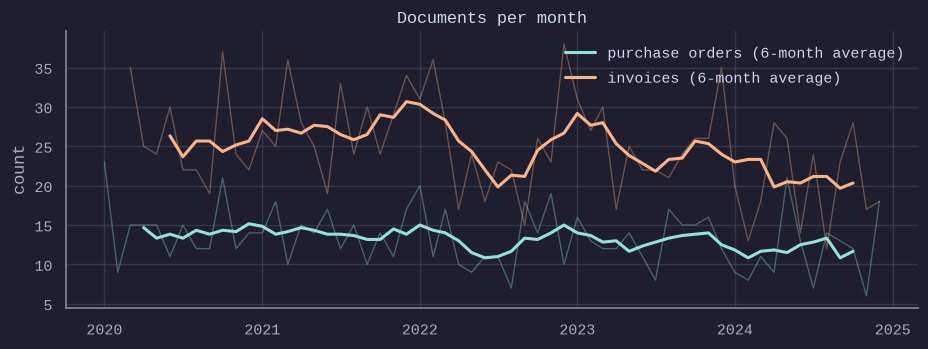

,purchase orders,invoices
count,60.0,58.0
mean,13.3,24.9
std,3.7,6.2
min,6.0,12.0
max,23.0,38.0


In [3]:
# Only complete months. POs run 2020-01 to 2024-12. Invoices follow their PO by 5 to 60 days, so the first
# invoice months (Jan-Feb 2020) miss POs from before the data starts, and Jan-Feb 2025 only hold invoices
# of late-2024 POs. Counting those edge months would draw a false ramp-up and a false drop.
m_po = po.set_index("po_date").resample("MS").size().rename("purchase orders").loc["2020-01":"2024-12"]
m_inv = inv.set_index("invoice_date").resample("MS").size().rename("invoices").loc["2020-03":"2024-12"]
monthly = pd.concat([m_po, m_inv], axis=1)

fig, ax = plt.subplots()
for col, colour in (("purchase orders", TEAL), ("invoices", PEACH)):
    ax.plot(monthly.index, monthly[col], color=colour, alpha=0.35, lw=1)
    ax.plot(monthly.index, monthly[col].rolling(6, center=True).mean(), color=colour, lw=2.2, label=f"{col} (6-month average)")
ax.set_title("Documents per month"); ax.set_ylabel("count"); ax.legend()
plt.show()

monthly.describe().loc[["count", "mean", "std", "min", "max"]].round(1)

## 2. Trend and seasonality
Classical decomposition on monthly counts: trend is a 12-month centred moving average, the seasonal index is the average ratio of the month to its trend.

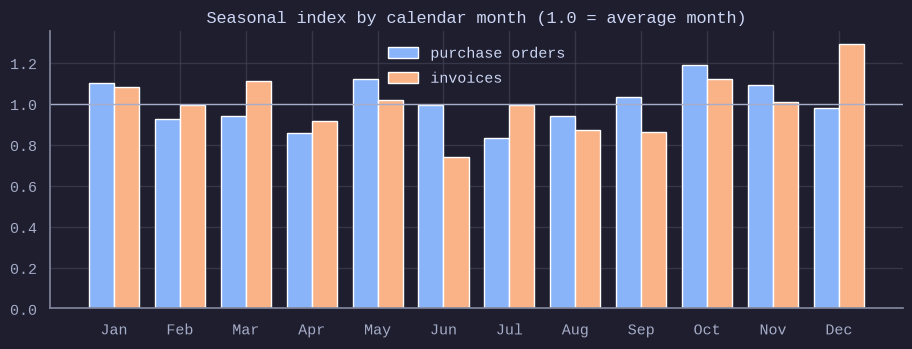

,POs,PO months,invoices,invoice months,PO change vs prior year,invoice change vs prior year
2020,174,12,260.0,10,NaN,NaN
2021,167,12,334.0,12,-0.040,NaN
2022,157,12,301.0,12,-0.060,-0.099
2023,161,12,306.0,12,0.025,0.017
2024,141,12,241.0,12,-0.124,-0.212


In [3]:
def seasonal_index(s):
    trend = s.rolling(12).mean().rolling(2).mean().shift(-6)  # centred 2x12 moving average
    ratio = (s / trend).dropna()
    idx = ratio.groupby(ratio.index.month).mean()
    return idx / idx.mean(), trend

si_po, tr_po = seasonal_index(monthly["purchase orders"])
si_inv, tr_inv = seasonal_index(monthly["invoices"])

fig, ax = plt.subplots()
w = 0.38
ax.bar(si_po.index - w / 2, si_po.values, w, color=BLUE, label="purchase orders")
ax.bar(si_inv.index + w / 2, si_inv.values, w, color=PEACH, label="invoices")
ax.axhline(1, color="#a6adc8", lw=1)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("Seasonal index by calendar month (1.0 = average month)"); ax.legend()
plt.show()

yearly = pd.concat([monthly["purchase orders"].groupby(monthly.index.year).agg(["sum", "count"]).add_prefix("PO "),
                    monthly["invoices"].groupby(monthly.index.year).agg(["sum", "count"]).add_prefix("invoice ")], axis=1)
yearly.columns = ["POs", "PO months", "invoices", "invoice months"]
# A change vs the prior year is only shown when both years have all 12 months of that series.
full = lambda c: yearly[c] == 12
yearly["PO change vs prior year"] = yearly["POs"].pct_change().where(full("PO months") & full("PO months").shift(fill_value=False)).round(3)
yearly["invoice change vs prior year"] = yearly["invoices"].pct_change().where(full("invoice months") & full("invoice months").shift(fill_value=False)).round(3)
yearly

Monthly counts are small (about 13 POs a month), so some spread between months appears even when there is no seasonality at all.
The test below shuffles the months 2,000 times and asks how often chance alone produces a spread (highest index minus lowest) as large as the real one.

In [4]:
import numpy as np
rng = np.random.default_rng(42)

def spread_p_value(s, trials=2000):
    trend = s.rolling(12).mean().rolling(2).mean().shift(-6)
    ratio = (s / trend).dropna()
    def spread(r, months):
        idx = r.groupby(months).mean()
        return (idx / idx.mean()).agg(lambda x: x.max() - x.min())
    real = spread(ratio, ratio.index.month)
    shuffled = [spread(ratio, rng.permutation(ratio.index.month)) for _ in range(trials)]
    return real, float(np.mean(np.array(shuffled) >= real))

pd.DataFrame({name: dict(zip(["spread of seasonal index", "chance of a spread this big with no seasonality"], spread_p_value(monthly[name].dropna())))
              for name in ["purchase orders", "invoices"]}).round(3)

,purchase orders,invoices
spread of seasonal index,0.358,0.549
chance of a spread this big with no seasonality,0.830,0.042


## 3. Purchase order value by currency
Not converted: the three lines are in three different currencies, so compare each line with itself, not with the others.

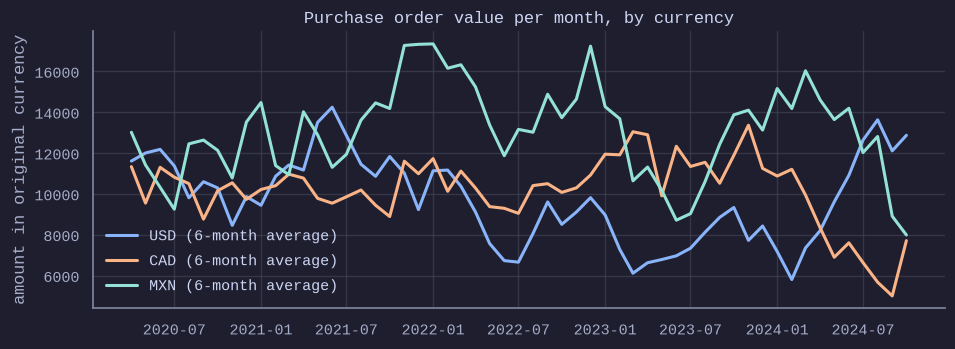

,orders,total,average,median
currency,,,,
CAD,256,614127.97,2398.94,2370.36
MXN,298,780578.64,2619.39,2861.92
USD,246,597342.88,2428.22,2395.98


In [5]:
amt = po.pivot_table(index=pd.Grouper(key="po_date", freq="MS"), columns="currency", values="amount", aggfunc="sum").fillna(0)
fig, ax = plt.subplots()
for cur, colour in zip(["USD", "CAD", "MXN"], [BLUE, PEACH, TEAL]):
    ax.plot(amt.index, amt[cur].rolling(6, center=True).mean(), color=colour, lw=2.2, label=f"{cur} (6-month average)")
ax.set_title("Purchase order value per month, by currency"); ax.set_ylabel("amount in original currency"); ax.legend()
plt.show()

po.groupby("currency")["amount"].agg(orders="size", total="sum", average="mean", median="median").round(2)

## 4. Time from purchase order to invoice

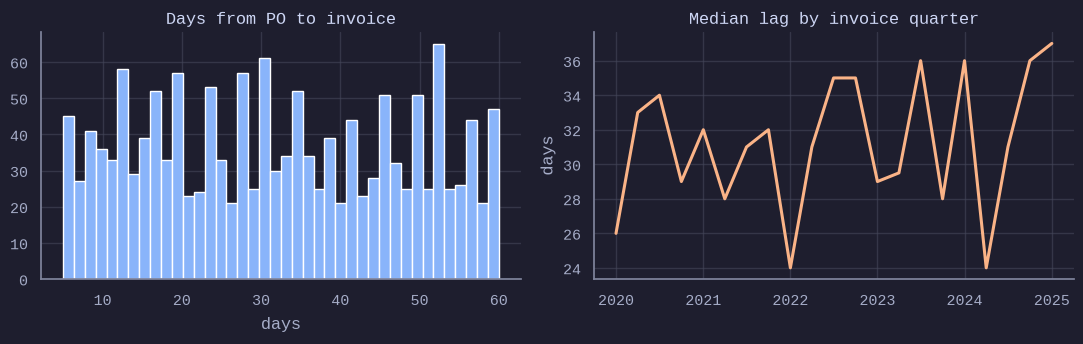

11 invoices have no purchase order and are left out here.
rank correlation between invoice date and lag: 0.017 (0 = no trend)


,days
count,1489.0
mean,31.9
std,16.0
min,5.0
25%,18.0
50%,31.0
75%,46.0
max,60.0


In [6]:
linked = inv.dropna(subset=["po_date"]).copy()
linked["lag_days"] = (linked.invoice_date - linked.po_date).dt.days

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(linked.lag_days, bins=40, color=BLUE)
axes[0].set_title("Days from PO to invoice"); axes[0].set_xlabel("days")
by_month = linked.set_index("invoice_date").lag_days.resample("QS").median()
axes[1].plot(by_month.index, by_month.values, color=PEACH, lw=2.2)
axes[1].set_title("Median lag by invoice quarter"); axes[1].set_ylabel("days")
plt.tight_layout(); plt.show()

print(f"{len(inv) - len(linked)} invoices have no purchase order and are left out here.")
trend = linked.assign(day=linked.invoice_date.map(pd.Timestamp.toordinal))[["day", "lag_days"]].corr(method="spearman").iloc[0, 1]
print(f"rank correlation between invoice date and lag: {trend:.3f} (0 = no trend)")
linked.lag_days.describe().round(1).to_frame("days")

## 5. Invoice coverage and payment

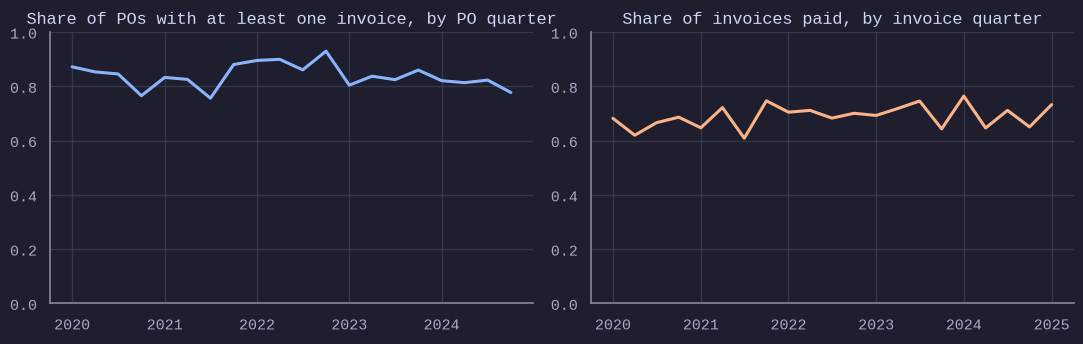

,value
POs without any invoice,128.000
share of POs without an invoice,0.160
unpaid invoices,470.000
share of invoices unpaid,0.313


In [4]:
po_has_invoice = po.po_id.isin(inv.po_id)
cover = po.assign(invoiced=po_has_invoice).set_index("po_date").invoiced.resample("QS").mean()
paid = inv.set_index("invoice_date").paid.astype(float).resample("QS").mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(cover.index, cover.values, color=BLUE, lw=2.2); axes[0].set_ylim(0, 1)
axes[0].set_title("Share of POs with at least one invoice, by PO quarter")
axes[1].plot(paid.index, paid.values, color=PEACH, lw=2.2); axes[1].set_ylim(0, 1)
axes[1].set_title("Share of invoices paid, by invoice quarter")
plt.tight_layout(); plt.show()

# Invoices arrive up to 60 days after the PO and the data ends on 2025-02-22, so POs after 2024-12-24 may simply not be invoiced yet.
pd.Series({
    "POs without any invoice": int((~po_has_invoice).sum()),
    "share of POs without an invoice": round(float((~po_has_invoice).mean()), 3),
    "unpaid invoices": int((~inv.paid).sum()),
    "share of invoices unpaid": round(float((~inv.paid).mean()), 3),
}).to_frame("value")

## What the data shows

- **Volume.** About 13 purchase orders and 25 invoices a month, roughly 1.9 invoices per PO.
- **Trend.** POs per year: 174, 167, 157, 161, 141 (2020 to 2024), down 19% overall. A single year-to-year change of 10% or so is within what chance alone produces for counts this small, so the 2024 drop (-12%) is a hint, not a finding. Invoices fell more in 2024 (-21%) after -10% and +2% in the two years before.
- **Seasonality.** None detectable for POs (chance alone gives a spread this big 83% of the time). Invoices show a weak hint (4%): high in December, low in June. With two series tested, treat it as a question to ask, not a result.
- **Value by currency.** The average order is 2,399 (CAD), 2,619 (MXN) and 2,428 (USD): nearly the same number in three currencies worth very different amounts. Either the amounts were not stored in each currency, or the generator ignored it. Worth asking the business before any amount is migrated.
- **Time to invoice.** Between 5 and 60 days, spread almost evenly (median 31), with no trend over time. Real invoices usually bunch around the payment terms, so this flat shape is unusual.
- **Coverage and payment.** 16% of POs (128) have no invoice and 31% of invoices (470) are unpaid; both shares stay roughly stable across the five years. POs after 24 December 2024 may simply not be invoiced yet.

**Caveats.** This reads the raw tables, so the 22 orphan POs and 11 orphan invoices are included (orphan invoices only drop out of the lag chart). Monthly series use complete months only. Amounts are never converted between currencies.